# Exploratory Data Analysis 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

## Overview of the dataframe

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.shape

(2443651, 9)

In [7]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


## Descriptive Statistics

In [16]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


Observation :
- 50% of the products have 0 reviews
- One product has more than 1 million of reviews

In [17]:
df.isnull()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
2443646,False,False,False,False,False,False,False,False,False
2443647,False,False,False,False,False,False,False,False,False
2443648,False,False,False,False,False,False,False,False,False
2443649,False,False,False,False,False,False,False,False,False


In [18]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [20]:
price_zero = (df['price'] == 0).sum()
price_zero

np.int64(20)

In [23]:
rating_zero = (df['stars'] ==0).sum()
rating_zero

np.int64(1225641)

In [24]:
reviews_zero = (df['reviews'] == 0).sum()
reviews_zero

np.int64(1225641)

In [26]:
df['price'].nlargest(10)

2008013    100000.00
1987238     77752.00
1905315     24674.59
1408966     23482.73
319555      22933.42
1490285     21999.00
1490286     21999.00
1907271     21464.82
1907272     21464.82
1907273     21464.82
Name: price, dtype: float64

In [9]:
list(set(df.dtypes.tolist()))

[dtype('int64'), dtype('bool'), dtype('O'), dtype('float64')]

In [10]:
df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [11]:
# Counting and sorting the unique values for each numerical column in descending order
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [12]:
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
potential_categorical_from_numerical

""
0
1
2
3
4
...
2443646
2443647
2443648
2443649


In [13]:
df.select_dtypes("object").columns

Index(['asin', 'title', 'category'], dtype='object')

In [14]:
# Counting and sorting the unique values for each object (string) column in descending order
df.select_dtypes("object").nunique().sort_values(ascending=False)

asin        2222742
title       2077591
category        296
dtype: int64

In [27]:
# Frequency table

df['category'].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [38]:
# Frequency in  percenage
df['category'].value_counts(normalize=True)*100

category
Sports & Outdoors                         34.221949
Beauty                                     0.790293
Handmade Clothing, Shoes & Accessories     0.786896
Bath & Body                                0.781290
Birthday Gifts                             0.776625
                                            ...    
Alexa Built-In Devices                     0.004379
Motorbike Chassis                          0.004379
Plugs                                      0.004379
Smart Home Security & Lighting             0.004256
Smart Speakers                             0.002210
Name: proportion, Length: 296, dtype: float64

In [37]:
# Which are the top 5 most listed product categories?
Top_5 = df['category'].value_counts().head(5)
print("The top 5 most listed product categories are:\n", Top_5)

The top 5 most listed product categories are:
 category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories*

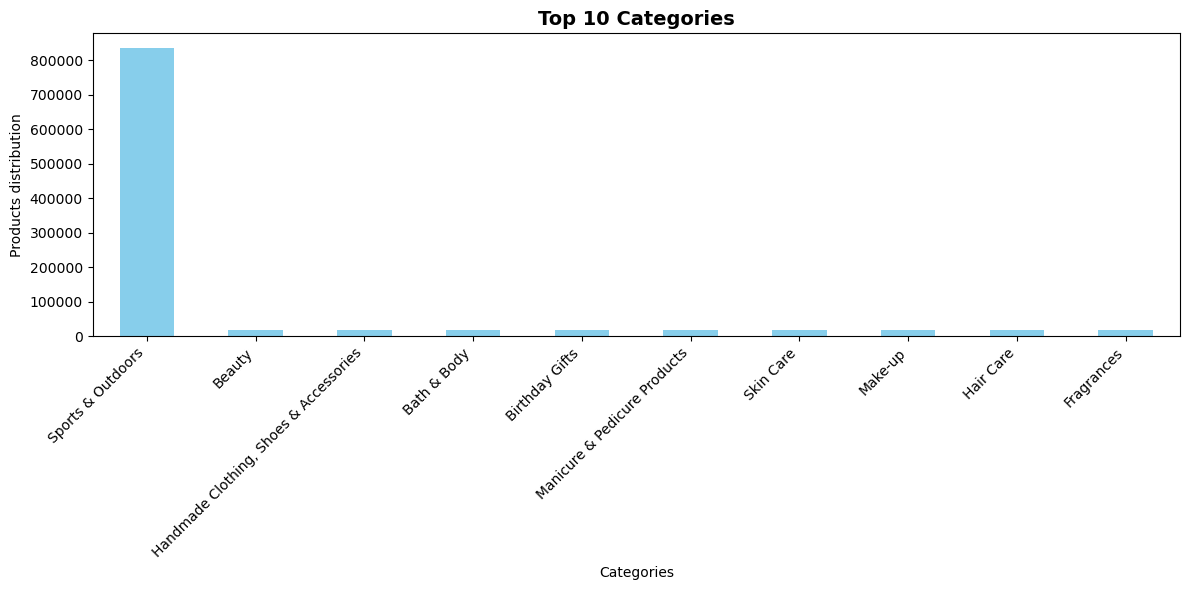

In [46]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6)) 
df['category'].value_counts().head(10).plot(kind='bar', color='skyblue')
plt.title('Top 10 Categories', fontsize=14, fontweight='bold')
plt.xlabel('Categories') 
plt.ylabel('Products distribution') 
plt.xticks(rotation=45, ha='right') 
plt.tight_layout() 
plt.show()

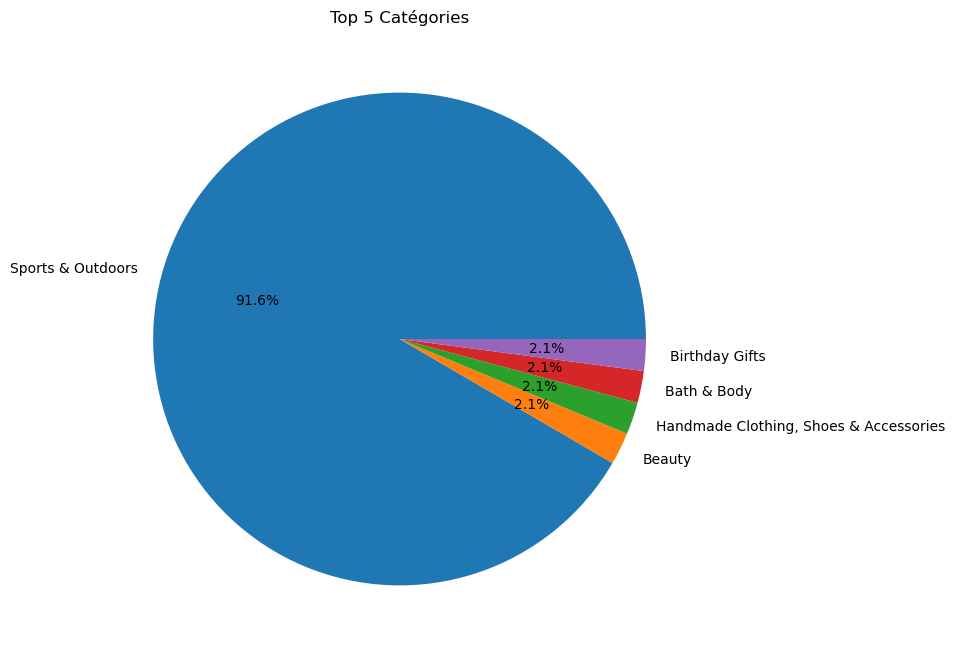

In [47]:
plt.figure(figsize=(8, 8)) 
df['category'].value_counts().head(5).plot(kind='pie', autopct='%1.1f%%') 
plt.title('Top 5 Catégories') 
plt.ylabel('')
plt.show()

Sports and outdoors are dominating the listings

Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [52]:
mean = df['price'].mean()
median = df['price'].median()
mode = df['price'].mode()[0]

print(mean, median, mode)

89.24380943923663 19.09 9.99


Measures of Centrality - Price

**Results:**
- Mean: £89.24
- Median: £19.09
- Mode: £9.99

**Analysis:**
The average price is £89.24, but the most common price (mode) is only £9.99. This large gap indicates the presence of expensive outliers that inflate the mean. The median (£19.09) is much closer to the mode, confirming that most products are priced affordably. This suggests a right-skewed distribution with a long tail of high-priced items.

In [53]:
variance = df['price'].var()
std = df['price'].std()
range = df['price'].max() - df['price'].min()
IQR = df['price'].quantile(0.75)- df['price'].quantile(0.25)

print (variance, std, range, IQR)

119445.4853225653 345.6088617535223 100000.0 36.0


 Measures of Dispersion - Price

**Results:**
- Variance: 119,445.49
- Standard Deviation: £345.61
- Range: £100,000
- IQR: £36.00

**Analysis:**
Product prices show extreme variation. The standard deviation (£345.61) is 18 times larger than the median price, indicating massive dispersion. However, the relatively small IQR (£36) reveals that the middle 50% of products are concentrated within a narrow price range. This stark contrast between IQR and standard deviation is a clear indicator that the overall price spread is driven by extreme outliers rather than general variability. Most products cluster in the affordable range (£10-46), while a small number of very expensive items create the massive overall dispersion.

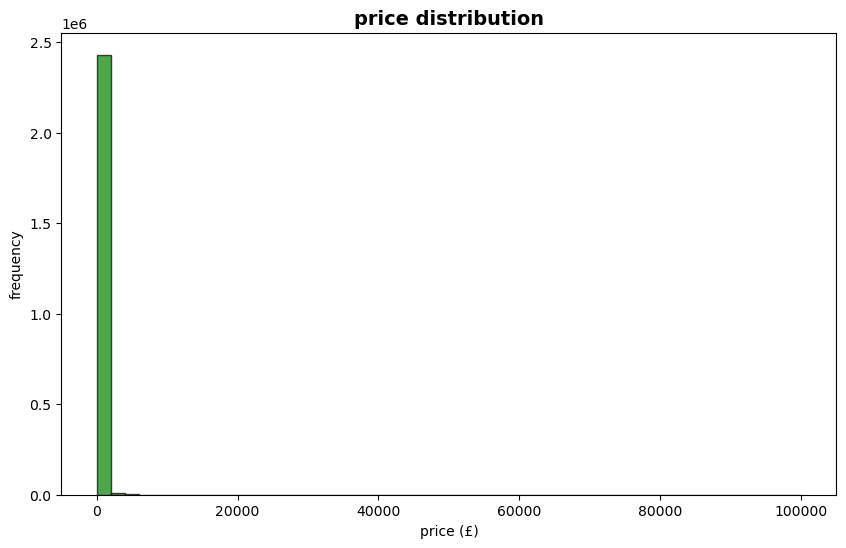

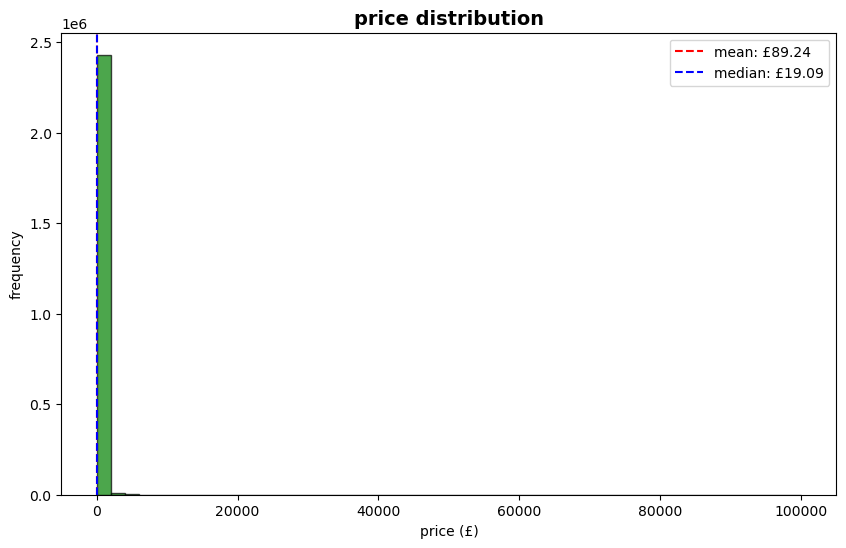

In [58]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(10, 6)) 
plt.hist(df['price'], bins=50, color='green', alpha=0.7, edgecolor='black') 
plt.title('price distribution', fontsize=14, fontweight='bold') 
plt.xlabel('price (£)') 
plt.ylabel('frequency') 
plt.axvline(mean, color='red', linestyle='--', label=f'mean: £{mean:.2f}') 
plt.axvline(median, color='blue', linestyle='--', label=f'median: £{median:.2f}') 
plt.legend() 
plt.show()

**Observation:**
The initial histogram and box plot are difficult to read because the x-axis scale extends to £100,000 to accommodate extreme outliers, while the vast majority of products (>95%) are priced below £100. This creates a visualization where nearly all data is compressed into a thin bar at the left side of the graph.

**Why this happens:**
The presence of extreme outliers (products priced at £100,000) forces the visualization scale to span a massive range, making it impossible to see the distribution of the majority of products.

**Solution:**
To better visualize the price distribution, we can either:
1. Filter the data to show only 95% of products (removing the top 5% outliers)
2. Limit the x-axis to a more reasonable range (e.g., 0-200£)

This allows us to clearly see that most products are concentrated in the £10-50 range.

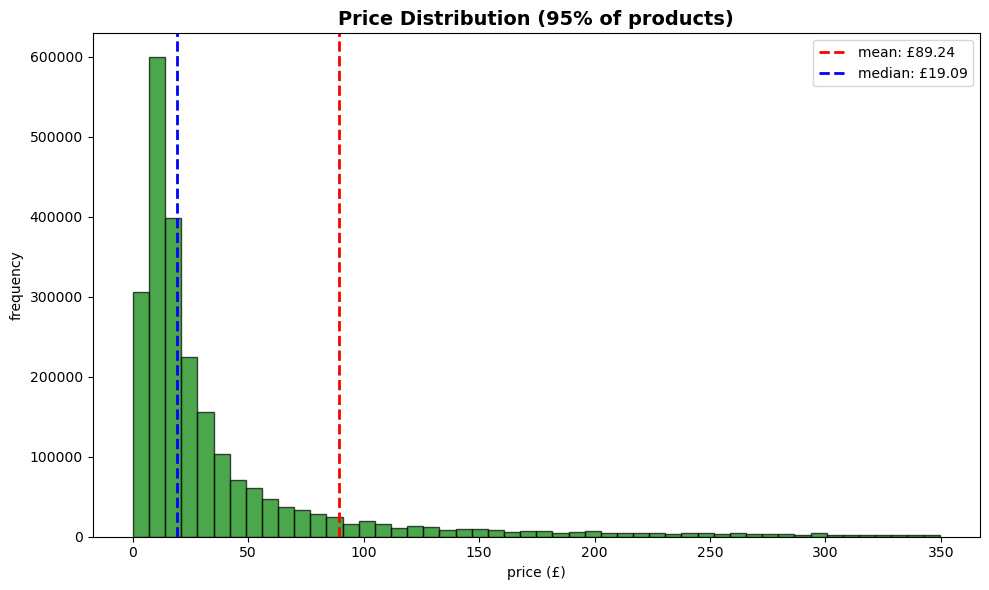

In [60]:
price_95 = df['price'].quantile(0.95)

df_filtered = df[df['price'] <= price_95]

plt.figure(figsize=(10, 6))
plt.hist(df_filtered['price'], bins=50, color='green', alpha=0.7, edgecolor='black')
plt.title('Price Distribution (95% of products)', fontsize=14, fontweight='bold')
plt.xlabel('price (£)')
plt.ylabel('frequency')


plt.axvline(mean, color='red', linestyle='--', linewidth=2, label=f'mean: £{mean:.2f}')
plt.axvline(median, color='blue', linestyle='--', linewidth=2, label=f'median: £{median:.2f}')
plt.legend()
plt.tight_layout()
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


In [63]:
mean_rat = df['stars'].mean()
median_rat = df['stars'].median()
mode_rat = df['stars'].mode()[0]

print(mean_rat, median_rat, mode_rat)

2.152836472966065 0.0 0.0


The median (0.0) and mode (0.0) indicate that at least 50% of products have no customer ratings. The mean of 2.15 stars includes these unrated products. The common trend is that products are split into two groups: those with no ratings (50%+) and those that have been reviewed by customers.

In [65]:
variance_rat = df['stars'].var()
std_rat = df['stars'].std()
range_rat = df['stars'].max() - df['stars'].min()
IQR_rat = df['stars'].quantile(0.75)- df['stars'].quantile(0.25)

print (variance_rat, std_rat, range_rat, IQR_rat)

4.81743402976196 2.1948653785054697 5.0 4.4


Customer feedback shows wide variation. The standard deviation (2.19) is high relative to the 5-star scale, and the IQR (4.4) spans nearly the entire rating range. This indicates ratings are not consistent - there is significant variability in customer feedback, largely due to the 50/50 split between unrated products (0 stars) and rated products (spanning 1-5 stars).


In [67]:
skewness_rat = df['stars'].skew()
kurtosis_rat = df['stars'].kurtosis()

print(f"Skewness : {skewness_rat:.4f}")
print(f"Kurtosis : {kurtosis_rat:.4f}")

Skewness : 0.0812
Kurtosis : -1.9260


The ratings are NOT normally distributed. The skewness (0.0812) is near zero, indicating symmetry - ratings do not lean towards higher or lower values. However, the negative kurtosis (-1.9260) reveals a flattened, platykurtic distribution rather than a normal bell curve. This flat distribution results from the 50/50 split between unrated products (0 stars) and rated products spread across the rating scale.

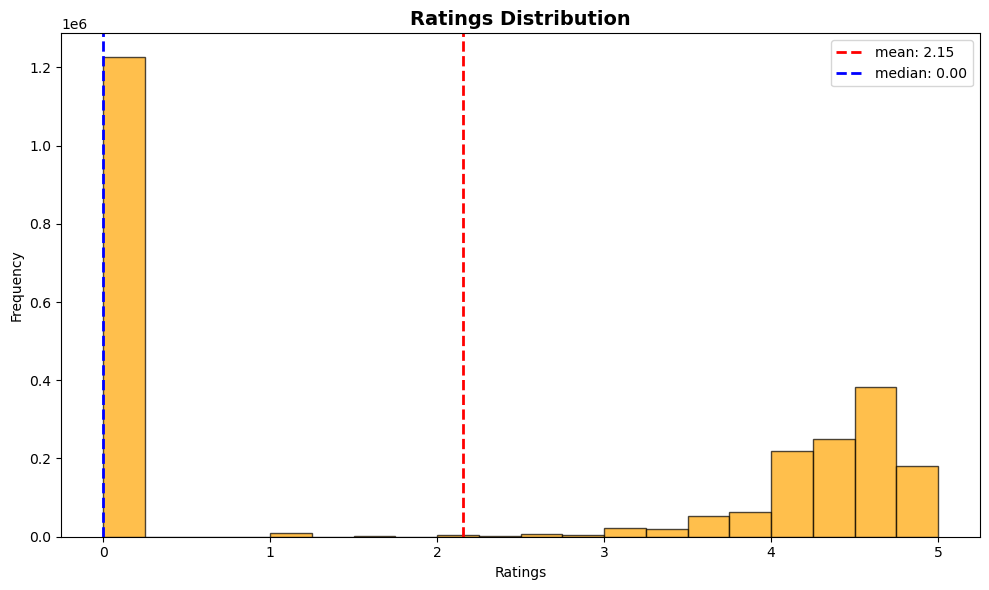

In [69]:
plt.figure(figsize=(10, 6))
plt.hist(df['stars'], bins=20, color='orange', alpha=0.7, edgecolor='black')
plt.title('Ratings Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Ratings')
plt.ylabel('Frequency')


plt.axvline(mean_rat, color='red', linestyle='--', linewidth=2, label=f'mean: {mean_rat:.2f}')
plt.axvline(median_rat, color='blue', linestyle='--', linewidth=2, label=f'median: {median_rat:.2f}')

plt.legend()
plt.tight_layout()
plt.show()

Yes, 0 stars is by far the most common "rating" with over 1.2 million products (50%+ of all listings). However, this represents unrated products rather than actual customer feedback.
